# 07 · Final evaluation and error analysis

**Data science step 7 of 7:** train the chosen model one last time and measure it **honestly** on data it has never seen.

**Input:** `examples_final.parquet` (from notebook 04, history learned from Sept 1–25)
**Train on:** Sept 1–25 (train + valid) · **Test on:** Sept 26–30, **used once, here, for the first time**

Why retrain on train + valid? All settings were chosen in notebook 06, so the valid days are no longer needed for decisions, and more data = a better model.

In [1]:
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

DATA = Path("data/processed")
FIGURES = Path("reports/figures")
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)

NUMERIC_FEATURES = [
    "cur_delay", "prev_delay", "delay_change", "origin_delay", "max_delay_so_far",
    "stop_no", "stops_left", "km_done", "km_left", "share_done",
    "sched_min_left", "planned_kmh_left", "total_km", "n_stops", "hour", "dow", "is_special",
    "hist_change", "hist_train_dest", "hist_station_gain", "hist_n_trips",
]
CATEGORICAL_FEATURES = ["zone", "train_type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

final = pd.read_parquet(DATA / "examples_final.parquet")
fit = final[final["split"] != "test"]
test = final[final["split"] == "test"]

X_fit, y_fit = fit[FEATURES], fit["target"].to_numpy()
X_test, y_test = test[FEATURES], test["target"].to_numpy()
print(f"fit: {len(fit):,} rows (Sept 1-25) | test: {len(test):,} rows (Sept 26-30)")

fit: 911,769 rows (Sept 1-25) | test: 187,674 rows (Sept 26-30)


In [2]:
def evaluate(y_true, y_pred):
    error = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return {
        "MAE": np.mean(np.abs(error)),
        "MedianAE": np.median(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "R2": 1 - np.sum(error ** 2) / np.sum((y_true - np.mean(y_true)) ** 2),
        "within_10min_%": 100 * np.mean(np.abs(error) <= 10),
        "within_30min_%": 100 * np.mean(np.abs(error) <= 30),
        "bias": np.mean(error),
    }


def historical_baseline(X):
    return np.clip(X["cur_delay"] + X["hist_change"].fillna(0), 0, None).to_numpy()

## Step 1: Train the final model
Exactly the settings chosen in notebook 06. The log shows the **training** error only. We don't look at the test set while training.

In [3]:
base_fit = historical_baseline(X_fit)

model = HistGradientBoostingRegressor(loss="absolute_error", max_iter=150, max_leaf_nodes=127,
                                      min_samples_leaf=100, l2_regularization=1.0, learning_rate=0.1,
                                      categorical_features="from_dtype", early_stopping=False, random_state=42)
start = time.time()
model.fit(X_fit, y_fit - base_fit)
print(f"trained {model.n_iter_} rounds in {time.time() - start:.1f}s\n")

sample = fit.sample(100_000, random_state=42)
base_sample = historical_baseline(sample[FEATURES])
for round_no, p in enumerate(model.staged_predict(sample[FEATURES]), start=1):
    if round_no == 1 or round_no % 25 == 0:
        mae = np.mean(np.abs(np.clip(base_sample + p, 0, None) - sample["target"]))
        print(f"round {round_no:>3}/150 | train MAE {mae:6.2f}")

trained 150 rounds in 21.0s

round   1/150 | train MAE  19.12
round  25/150 | train MAE  16.55


round  50/150 | train MAE  16.01
round  75/150 | train MAE  15.68
round 100/150 | train MAE  15.38
round 125/150 | train MAE  15.18


round 150/150 | train MAE  14.95


## Step 2: The test score
The final model against the same three baselines, all on Sept 26–30:

In [4]:
predictions = {
    "Final model": np.clip(historical_baseline(X_test) + model.predict(X_test), 0, None),
    "Historical baseline": historical_baseline(X_test),
    "Persistence": X_test["cur_delay"].to_numpy(),
    "Zero (always on time)": np.zeros(len(test)),
}
test_results = pd.DataFrame({name: evaluate(y_test, p) for name, p in predictions.items()}).T.round(2)
test_results.to_csv("reports/test_results.csv")
test_results

,MAE,MedianAE,RMSE,R2,within_10min_%,within_30min_%,bias
Final model,15.51,0.16,49.99,0.74,75.72,87.69,-8.18
Historical baseline,19.10,4.00,52.31,0.71,65.09,84.43,-1.16
Persistence,25.02,9.00,60.25,0.62,52.67,78.39,-1.46
Zero (always on time),29.83,0.00,102.40,-0.09,75.27,84.33,-29.83


In [5]:
improvement = lambda base: 100 * (1 - test_results.loc["Final model", "MAE"] / test_results.loc[base, "MAE"])
print(f"Final model MAE: {test_results.loc['Final model', 'MAE']:.1f} min")
print(f"  {improvement('Historical baseline'):.0f}% better than the historical baseline")
print(f"  {improvement('Persistence'):.0f}% better than persistence")

Final model MAE: 15.5 min
  19% better than the historical baseline
  38% better than persistence


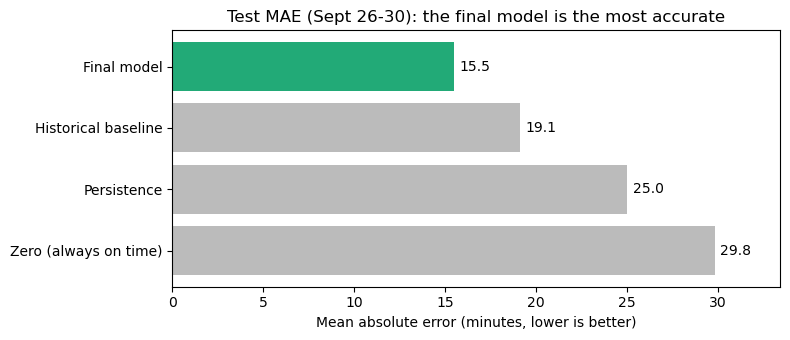

In [6]:
order = test_results["MAE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(order.index, order.values, color=["#bbb", "#bbb", "#bbb", "#2a7"])
for i, v in enumerate(order.values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center")
ax.set_xlim(0, order.max() * 1.12)
ax.set_title("Test MAE (Sept 26-30): the final model is the most accurate")
ax.set_xlabel("Mean absolute error (minutes, lower is better)")
plt.tight_layout()
plt.savefig(FIGURES / "test_mae.png", dpi=120)
plt.show()

The test MAE (≈15.5) is a little worse than on valid (≈14.7). That's normal: test days are further in the future, and some trains behave differently. Because the test set was never used for any decision, **this is the number to report.**

## Step 3: Predicted vs actual
Perfect predictions would sit on the dashed diagonal. Colour = how many examples fall in each spot (log scale).

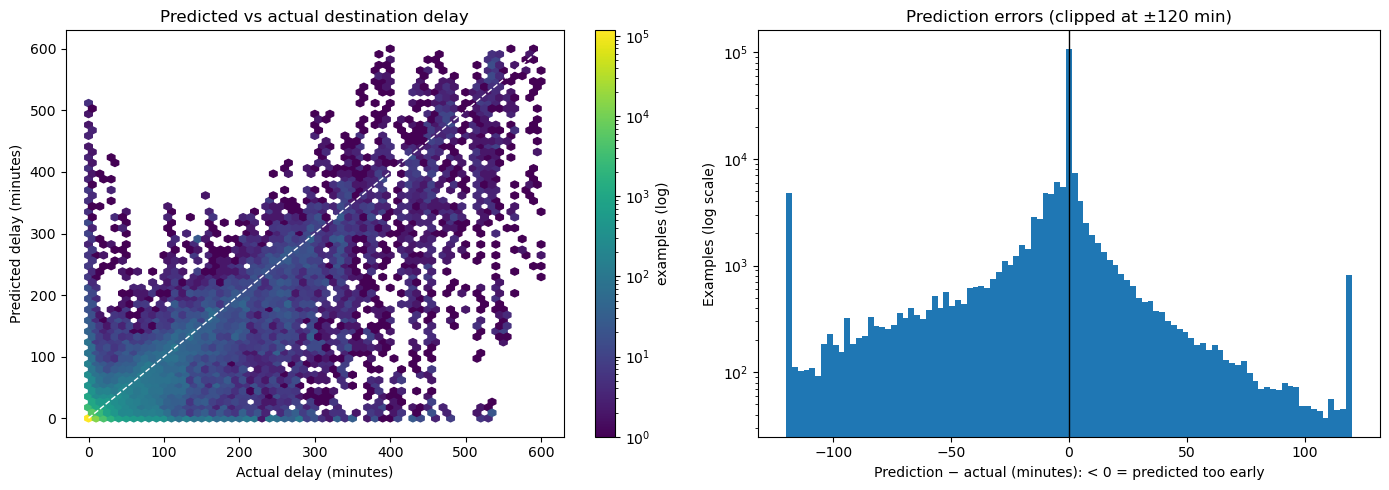

In [7]:
pred = predictions["Final model"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hb = axes[0].hexbin(y_test, pred, gridsize=60, bins="log", extent=(0, 600, 0, 600), mincnt=1, cmap="viridis")
axes[0].plot([0, 600], [0, 600], "w--", lw=1)
axes[0].set_title("Predicted vs actual destination delay")
axes[0].set_xlabel("Actual delay (minutes)")
axes[0].set_ylabel("Predicted delay (minutes)")
fig.colorbar(hb, ax=axes[0], label="examples (log)")

errors = pred - y_test
axes[1].hist(np.clip(errors, -120, 120), bins=97)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_yscale("log")
axes[1].set_title("Prediction errors (clipped at ±120 min)")
axes[1].set_xlabel("Prediction − actual (minutes): < 0 = predicted too early")
axes[1].set_ylabel("Examples (log scale)")
plt.tight_layout()
plt.savefig(FIGURES / "predicted_vs_actual.png", dpi=120)
plt.show()

- Most points hug the diagonal at small delays: **very accurate for on-time and slightly late trains**
- Above ~150 minutes actual delay, the points sit **below** the diagonal: big delays are **underestimated**
- The error histogram has a long **left** tail (predicted too early) for the same reason

## Step 4: Where is the model wrong?
### 4a. By how far the train still has to go

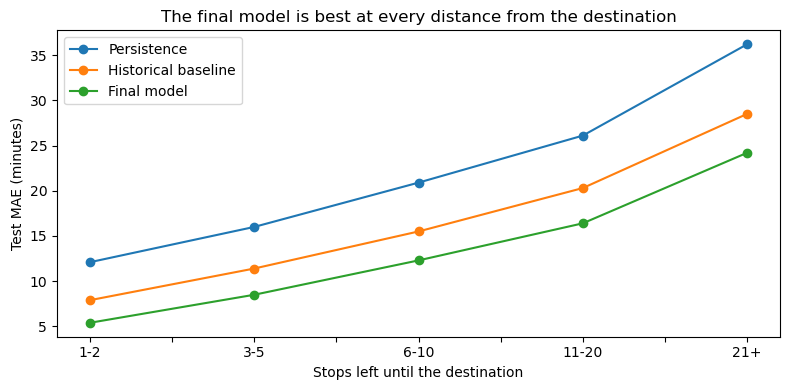

,Persistence,Historical baseline,Final model
stops left,,,
1-2,12.1,7.9,5.4
3-5,16.0,11.4,8.5
6-10,20.9,15.5,12.3
11-20,26.1,20.3,16.4
21+,36.2,28.5,24.2


In [8]:
compare = {k: predictions[k] for k in ["Persistence", "Historical baseline", "Final model"]}
stops_bucket = pd.cut(test["stops_left"], [0, 2, 5, 10, 20, 200], labels=["1-2", "3-5", "6-10", "11-20", "21+"])

by_stops = pd.DataFrame({name: np.abs(p - y_test) for name, p in compare.items()})
by_stops["stops left"] = stops_bucket.values
by_stops = by_stops.groupby("stops left", observed=True).mean().round(1)

ax = by_stops.plot(marker="o", figsize=(8, 4))
ax.set_title("The final model is best at every distance from the destination")
ax.set_xlabel("Stops left until the destination")
ax.set_ylabel("Test MAE (minutes)")
plt.tight_layout()
plt.savefig(FIGURES / "test_mae_by_stops_left.png", dpi=120)
plt.show()
by_stops

### 4b. By how late the train really was

In [9]:
actual_bucket = pd.cut(y_test, [-1, 0, 15, 60, 180, 2000], labels=["on time", "1-15", "16-60", "61-180", "181+"])
pd.DataFrame({"actual delay": actual_bucket, "error": errors}).groupby("actual delay", observed=True)["error"].agg(
    examples="size", MAE=lambda e: e.abs().mean(), bias="mean").round(1)

,examples,MAE,bias
actual delay,,,
on time,122380,2.9,2.9
1-15,26676,8.5,-2.3
16-60,16684,23.7,-12.4
61-180,12643,54.9,-40.6
181+,9291,134.1,-119.0


**This is the model's main weakness.** For trains that end up **3+ hours late**, it predicts about 2 hours too early on average (bias ≈ −119). Absolute loss aims at the *typical* outcome, and very large delays are rare and hard to foresee from the middle of a journey (breakdowns, diversions, a lost path on busy track). For on-time and slightly late trains, it's very accurate.

### 4c. By zone and by train type

In [10]:
def mae_by(groups):
    frame = pd.DataFrame({"group": groups.values, "abs_error": np.abs(errors)})
    return frame.groupby("group", observed=True)["abs_error"].agg(examples="size", MAE="mean").round(1).sort_values("MAE", ascending=False)

mae_by(test["zone"]).head(8)

,examples,MAE
group,,
SECR,4023,37.3
NE,7465,28.6
SER,5712,25.4
CR,13325,22.7
NCR,10014,21.3
ECOR,8673,21.0
WCR,10654,20.0
NR,22485,19.2


In [11]:
mae_by(test["train_type"])

,examples,MAE
group,,
special,9153,40.1
duronto,354,34.7
garib_rath,947,22.0
humsafar,632,16.2
rajdhani,867,16.0
express,148687,14.6
superfast,16003,13.4
local,5545,11.4
jan_shatabdi,1804,7.3


**Special/festival trains are by far the hardest** (MAE ≈ 40): they often get low priority on busy track, so their delays are large and irregular. Premium trains (**Vande Bharat, Shatabdi, Jan Shatabdi**) are very predictable (MAE under 8). SECR (South East Central) is the hardest zone, part of the same freight-heavy region.

## Step 5: One real journey, stop by stop
Azad Hind Express (12130), Howrah → Pune, on 27 September: a test journey the model never saw.

In [12]:
names = (pd.read_csv("Indian-Railway-Network-and-Delays/train_routes_Sep2024.csv", dtype={"trainNumber": str})
         .drop_duplicates("station_code").set_index("station_code")["station_name"])

rows = ((test["train"] == "12130") & (test["date"] == "2024-09-27")).to_numpy()
journey = test[rows].assign(station_name=lambda d: d["station"].map(names),
                            predicted=pred[rows].round(),
                            actual=y_test[rows])
journey[["station_name", "stops_left", "cur_delay", "predicted", "actual"]].iloc[::3]

,station_name,stops_left,cur_delay,predicted,actual
186795,Howrah,31,215.0,669.0,360.0
186798,Rourkela,27,314.0,656.0,360.0
186801,Raigarh,24,333.0,397.0,360.0
186804,Bhatapara,21,361.0,406.0,360.0
186807,Raj Nandgaon,18,363.0,440.0,360.0
186810,Bhandara Road,14,393.0,456.0,360.0
186813,Badnera,11,419.0,453.0,360.0
186816,Malkapur,8,415.0,456.0,360.0
186819,Manmad,5,433.0,440.0,360.0
186822,Ahmadnagar,2,413.0,405.0,360.0


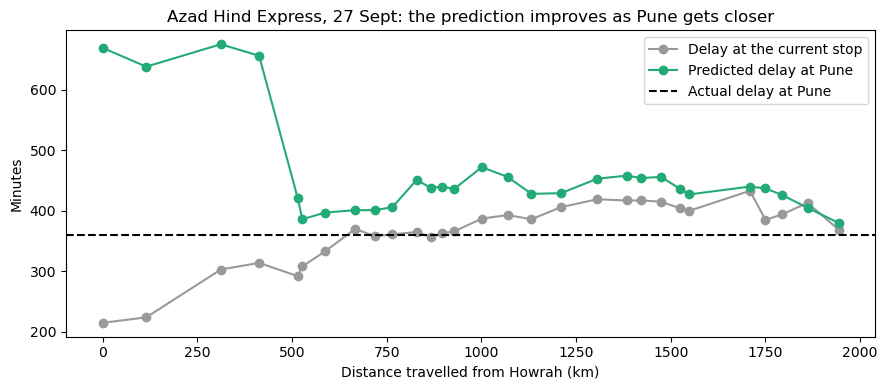

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(journey["km_done"], journey["cur_delay"], "o-", color="#999", label="Delay at the current stop")
ax.plot(journey["km_done"], journey["predicted"], "o-", color="#2a7", label="Predicted delay at Pune")
ax.axhline(journey["actual"].iloc[0], color="black", ls="--", label="Actual delay at Pune")
ax.set_title("Azad Hind Express, 27 Sept: the prediction improves as Pune gets closer")
ax.set_xlabel("Distance travelled from Howrah (km)")
ax.set_ylabel("Minutes")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "example_journey.png", dpi=120)
plt.show()

- **First ~400 km:** the model predicts ≈650+ minutes, far above the real 360. This train usually loses hours on this stretch (the freight belt around Rourkela, Challenge 4), and history says that delay tends to grow.
- **After ~500 km:** the guess drops to ≈400 and then follows the current delay, staying a little **above** it: the model expects a bit more time to be lost, but on this day the train held its delay.
- **One stop before Pune:** ≈380 vs 360 actual.

The further from the destination, the less certain the prediction. Even on a day that went better than usual, it ends within about 20 minutes.

## Step 6: What does the model rely on? (permutation importance)
For each feature: **shuffle** its values (destroying its information), predict again, and measure how much worse the MAE gets. Big increase = the model depends on it.

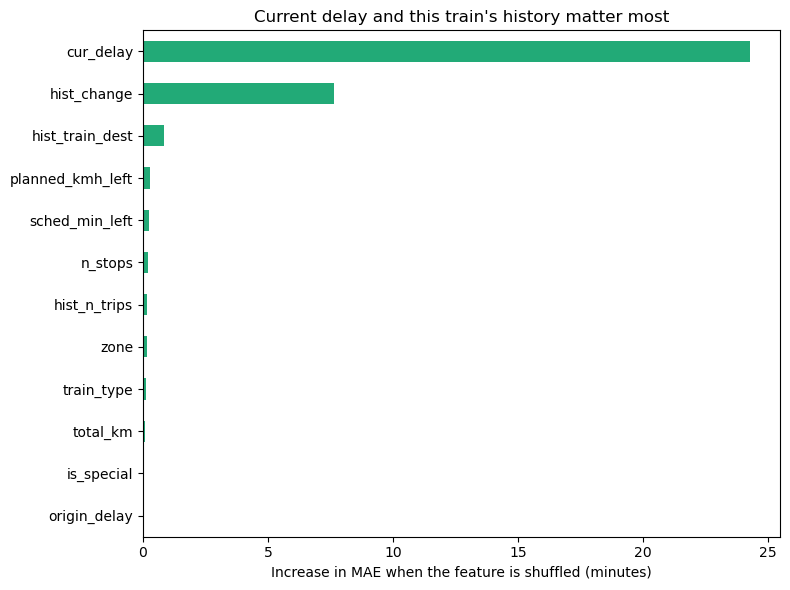

In [14]:
check = test.sample(20_000, random_state=42)
X_check, y_check = check[FEATURES], check["target"].to_numpy()


def predict(X):
    return np.clip(historical_baseline(X) + model.predict(X), 0, None)


base_mae = np.mean(np.abs(predict(X_check) - y_check))
rng = np.random.default_rng(42)
importance = {}
for feature in FEATURES:
    shuffled = X_check.copy()
    shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
    importance[feature] = np.mean(np.abs(predict(shuffled) - y_check)) - base_mae
importance = pd.Series(importance).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
importance.tail(12).plot.barh(ax=ax, color="#2a7")
ax.set_title("Current delay and this train's history matter most")
ax.set_xlabel("Increase in MAE when the feature is shuffled (minutes)")
plt.tight_layout()
plt.savefig(FIGURES / "feature_importance.png", dpi=120)
plt.show()

Almost all of the model's knowledge comes from **two features**: the current delay, and this train's usual change from this station (`hist_change`). The timetable, zone and train-type features add a little on top.

## Step 7: Save the model
The baseline formula is saved together with the trees, so the model can be used later without this notebook.

In [15]:
joblib.dump({"model": model, "features": FEATURES,
             "baseline": "cur_delay + hist_change (0 if missing), clipped at 0"},
            MODELS / "final_model.joblib")
print("saved", MODELS / "final_model.joblib")

saved models/final_model.joblib


## Conclusions
| | |
|---|---|
| **Task** | Predict the delay at the final destination from any stop of a journey |
| **Final model** | Historical baseline + gradient-boosted correction (absolute loss, 150 trees) |
| **Test MAE** | **≈15.5 min**, ~19% better than the historical rule, ~38% better than persistence |
| **Within ±10 min** | ≈76% of predictions |
| **Main weakness** | Delays of 3+ hours are underestimated |

**Biggest lesson:** the largest gain came from **framing** (learning the correction to a baseline), not from a more complex algorithm. The neural network and the plain boosting models didn't beat the simple historical rule.

### Limitations
- Only **one month** of data: no seasons, monsoon or festival peaks
- Fake zeros at the very **start** of a journey can't be detected
- No data on congestion, weather or maintenance work

### Next steps
- **Prediction intervals** ("10–45 minutes late") with quantile loss
- A **classification** model: "will it be more than 15 minutes late?"
- **Network features** from `IRN_edges.csv`: how busy the track ahead is

### 🧠 Try it yourself
1. Load `models/final_model.joblib` in a new notebook and predict for one row of `test`. Do you get the same number as here?
2. Train a second model with `loss="quantile", quantile=0.9`. What does it predict, and who would use it?
3. Pick the zone with the highest MAE. Plot one of its test journeys like Step 5. Why is it hard to predict?